# RBP conservation: a walkthrough

Which file answers which question, with a runnable example for each. Run the cells top to bottom;
change `GENE` in sections 3 and 4 to look at any RBP.

| Question | File | One row per |
|---|---|---|
| Which RBPs are most or least conserved? | `results/tables/rbp_conservation_simple.tsv` | RBP |
| Details for one RBP (orthologs, all four scores, mapping QC) | `results/tables/rbp_conservation_scores.tsv` | RBP |
| Which stretch of a protein is conserved? | `results/per_base/rbp_per_residue_scores.tsv.gz` | amino-acid residue |
| What does conservation look like base by base? | `results/per_base/rbp_cds_per_base_scores.parquet` | coding base |

Every column is explained in `COLUMNS.md`. phyloP reads: about 0 is neutral, about 2 is typical of a coding exon,
about 5 or more is strongly constrained (positive = conserved, negative = faster than expected).

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PAL = dict(light="#8ecae6", mid="#219ebc", dark="#023047", gold="#ffb703", orange="#fb8500")
mpl.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": PAL["dark"], "axes.labelcolor": PAL["dark"], "text.color": PAL["dark"],
                     "xtick.color": PAL["dark"], "ytick.color": PAL["dark"], "figure.dpi": 110})

simple = pd.read_csv(ROOT / "results/tables/rbp_conservation_simple.tsv", sep="\t")
scores = pd.read_csv(ROOT / "results/tables/rbp_conservation_scores.tsv", sep="\t")
print(simple.shape, scores.shape)
simple.head(3)

(2335, 10) (2335, 93)


,GeneSymbol,UniProtID,cds_phyloP_100way,conservation_percentile,conservation_tier,mouse_protein_identity_pct,n_species_with_ortholog,deepest_ortholog_species,score_reliable,reliability_note
0,A1CF,Q9NQ94,4.744,75.5,high,93.4,7.0,drerio,True,NaN
1,AAMP,Q13685,4.035,55.0,medium,98.4,10.0,scerevisiae,True,NaN
2,AAR2,Q9Y312,3.761,48.2,medium,90.6,10.0,scerevisiae,True,NaN


## 1. Rank the RBPs

`cds_phyloP_100way` is the mean phyloP over an RBP's coding sequence. Keep `score_reliable == True` (mapped, scored isoform
covers at least 90% of your protein, enough alignment data) so unreliable rows do not reach the top or bottom of the list.

In [2]:
ok = simple[simple.score_reliable].sort_values("cds_phyloP_100way", ascending=False)
cols = ["GeneSymbol", "cds_phyloP_100way", "conservation_percentile", "mouse_protein_identity_pct",
        "deepest_ortholog_species"]
print(f"{len(ok)} reliable RBPs of {len(simple)}")
print("Most conserved:");  display(ok[cols].head(8).round(2))
print("Least conserved:"); display(ok[cols].tail(8).round(2))

2321 reliable RBPs of 2335
Most conserved:


,GeneSymbol,cds_phyloP_100way,conservation_percentile,mouse_protein_identity_pct,deepest_ortholog_species
1924,SRP54,6.33,100.0,99.8,scerevisiae
1832,SF3B5,6.32,100.0,98.8,dmelanogaster
1285,PAFAH1B1,6.30,99.9,99.8,scerevisiae
232,CELF2,6.25,99.9,93.6,scerevisiae
414,DDX6,6.22,99.8,97.7,drerio
608,ETF1,6.20,99.8,100.0,scerevisiae
562,ELAVL4,6.20,99.7,96.1,celegans
1714,RPS27A,6.19,99.7,99.4,xtropicalis


Least conserved:


,GeneSymbol,cds_phyloP_100way,conservation_percentile,mouse_protein_identity_pct,deepest_ortholog_species
780,HLA-A,-0.09,0.3,42.8,drerio
589,EPPK1,-0.14,0.3,75.3,xtropicalis
368,DCD,-0.19,0.3,NaN,ptroglodytes
843,IFI16,-0.32,0.2,42.4,rnorvegicus
972,LUZP4,-0.37,0.2,NaN,ptroglodytes
1191,NLRP11,-0.50,0.1,NaN,mmulatta
1023,MKI67,-0.51,0.1,41.8,xtropicalis
147,BST2,-0.57,0.0,37.2,rnorvegicus


## 2. Compare groups of RBPs

Your list flags ribosomal, spliceosomal and other RNP-machine proteins. A jittered strip shows every RBP, and the bar is the
median. The Mann-Whitney test asks whether one group tends to score higher than another. A small p-value means the difference
is unlikely to be chance; it does not say how big it is, so look at the medians too.

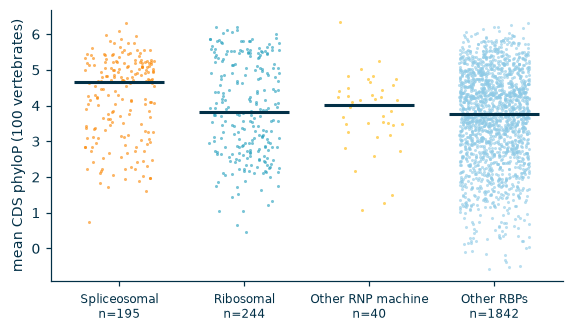

median spliceosomal 4.67 vs all others 3.78;  Mann-Whitney p = 6.0e-09


In [3]:
d = scores[scores.match_type != "none"].merge(simple[["UniProtID", "score_reliable"]], on="UniProtID")
d = d[d.score_reliable]
def cls(r):
    if r.Spliceosomal_protein == "Y": return "Spliceosomal"
    if r.Ribosomal_protein == "Y": return "Ribosomal"
    if r.Other_RNP_machine == "Y": return "Other RNP machine"
    return "Other RBPs"
d["group"] = d.apply(cls, axis=1)
order = ["Spliceosomal", "Ribosomal", "Other RNP machine", "Other RBPs"]
colors = dict(zip(order, [PAL["orange"], PAL["mid"], PAL["gold"], PAL["light"]]))
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(6, 3.2))
for i, g in enumerate(order):
    v = d.loc[d.group == g, "phyloP100way_mean"]
    ax.scatter(i + rng.uniform(-.28, .28, len(v)), v, s=4, color=colors[g], alpha=.6, linewidths=0)
    ax.hlines(v.median(), i - .36, i + .36, color=PAL["dark"], lw=2)
ax.set_xticks(range(4)); ax.set_xticklabels([f"{g}\nn={(d.group == g).sum()}" for g in order], fontsize=8)
ax.set_ylabel("mean CDS phyloP (100 vertebrates)")
plt.show()
a = d.loc[d.group == "Spliceosomal", "phyloP100way_mean"]; b = d.loc[d.group != "Spliceosomal", "phyloP100way_mean"]
print(f"median spliceosomal {a.median():.2f} vs all others {b.median():.2f};  Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.1e}")

## 3. One gene, every base

The per-base table has one row per coding base. Plot it for one RBP and colour by codon position: positions 1 and 2 carry
the protein-level constraint, position 3 is mostly silent and near neutral.

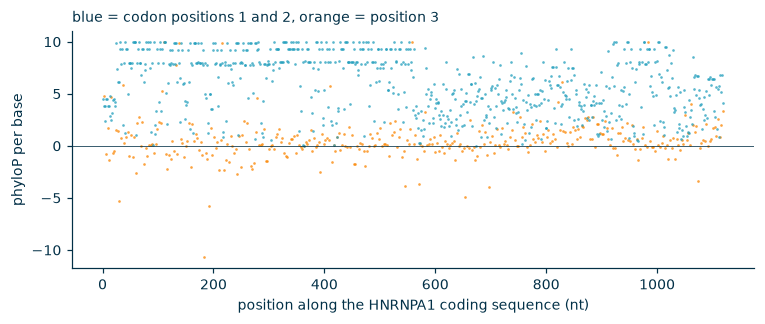

codon_position                    1     2     3
mean phyloP by codon position  5.62  6.27  0.54


In [4]:
GENE = "HNRNPA1"
base = pd.read_parquet(ROOT / "results/per_base/rbp_cds_per_base_scores.parquet")
g = base[base.GeneSymbol == GENE].sort_values("cds_pos")
fig, ax = plt.subplots(figsize=(8, 2.8))
for cp, c in [(3, PAL["orange"]), (1, PAL["mid"]), (2, PAL["mid"])]:
    s = g[g.codon_position == cp]
    ax.scatter(s.cds_pos, s.phyloP100way, s=3, color=c, alpha=.75, linewidths=0)
ax.axhline(0, color=PAL["dark"], lw=.5)
ax.set_xlabel(f"position along the {GENE} coding sequence (nt)"); ax.set_ylabel("phyloP per base")
ax.set_title("blue = codon positions 1 and 2, orange = position 3", loc="left", fontsize=9)
plt.show()
print(g.groupby("codon_position").phyloP100way.mean().round(2).rename("mean phyloP by codon position").to_frame().T)

## 4. One gene, residue by residue

The per-residue table averages each codon. Using only codon positions 1 and 2 (`phyloP100way_pos12_mean`) leaves out the
noisy third position. A rolling average over 15 residues shows which stretches of the protein are conserved (often folded
domains) and which are not (often disordered regions). Domain and disorder boundaries are not in this table, so compare the
curve with your own domain annotation.

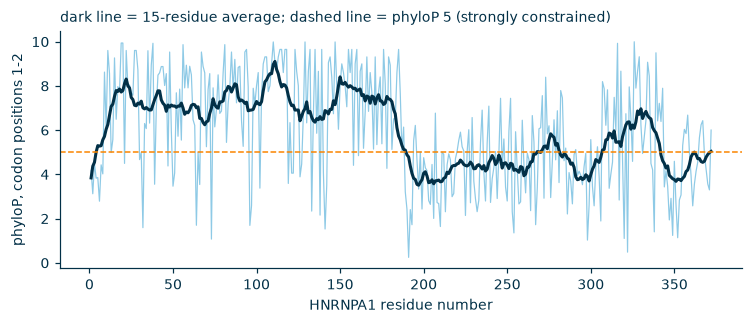

most conserved 15-residue window is centred on residue 111 (mean 9.1); least conserved on residue 197 (mean 3.5)


In [5]:
res = pd.read_csv(ROOT / "results/per_base/rbp_per_residue_scores.tsv.gz", sep="\t")
r = res[res.GeneSymbol == GENE].sort_values("residue_number").copy()
r["smooth"] = r.phyloP100way_pos12_mean.rolling(15, center=True, min_periods=8).mean()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(r.residue_number, r.phyloP100way_pos12_mean, color=PAL["light"], lw=.8)
ax.plot(r.residue_number, r.smooth, color=PAL["dark"], lw=2)
ax.axhline(5, color=PAL["orange"], lw=1, ls="--")
ax.set_title("dark line = 15-residue average; dashed line = phyloP 5 (strongly constrained)", loc="left", fontsize=9)
ax.set_xlabel(f"{GENE} residue number"); ax.set_ylabel("phyloP, codon positions 1-2")
plt.show()
w = r.dropna(subset=["smooth"])
hi, lo = w.loc[w.smooth.idxmax()], w.loc[w.smooth.idxmin()]
print(f"most conserved 15-residue window is centred on residue {int(hi.residue_number)} (mean {hi.smooth:.1f}); "
      f"least conserved on residue {int(lo.residue_number)} (mean {lo.smooth:.1f})")

## 5. A cleaner per-RBP score: positions 1 and 2 only

The headline score averages all three codon positions, which dilutes the protein-level signal with the near-neutral third
position. Scoring each RBP from positions 1 and 2 only gives a cleaner measure of protein-level constraint. Check how much
it changes the ranking: points on the diagonal rank the same either way, and points above it rank higher by the cleaner score.

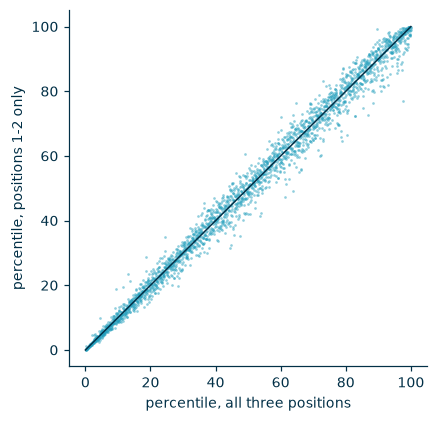

Spearman between the two rankings: 0.99
HNRNPA1: percentile 57 by all three positions, 64 by positions 1-2
Rank higher by positions 1-2: HSPA1A, MAT1A, FLNA, H1-5, H1-4, H1-2
Rank lower by positions 1-2:  RPL41, TNRC6B, PPARGC1A, YBX1, TNRC6A, PCNP


In [6]:
m12 = base[base.codon_position < 3].groupby("GeneSymbol").phyloP100way.mean().rename("pos12")
m123 = base.groupby("GeneSymbol").phyloP100way.mean().rename("all3")
cmp_ = pd.concat([m123, m12], axis=1).join(simple.set_index("GeneSymbol").score_reliable).query("score_reliable")
cmp_["rank_all3"] = cmp_.all3.rank(pct=True) * 100; cmp_["rank_pos12"] = cmp_.pos12.rank(pct=True) * 100
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.scatter(cmp_.rank_all3, cmp_.rank_pos12, s=3, color=PAL["mid"], alpha=.5, linewidths=0)
ax.plot([0, 100], [0, 100], color=PAL["dark"], lw=1)
ax.set_xlabel("percentile, all three positions"); ax.set_ylabel("percentile, positions 1-2 only")
plt.show()
cmp_["shift"] = cmp_.rank_pos12 - cmp_.rank_all3
print(f"Spearman between the two rankings: {stats.spearmanr(cmp_.all3, cmp_.pos12)[0]:.2f}")
print(f"{GENE}: percentile {cmp_.loc[GENE, 'rank_all3']:.0f} by all three positions, {cmp_.loc[GENE, 'rank_pos12']:.0f} by positions 1-2")
print("Rank higher by positions 1-2:", ", ".join(cmp_.nlargest(6, "shift").index))
print("Rank lower by positions 1-2: ", ", ".join(cmp_.nsmallest(6, "shift").index))

## 6. Combine with your own annotation

Everything joins on `GeneSymbol` or `UniProtID`. As an example, median conservation by HGNC gene family, using the family
column from your RBP list (families with at least 8 reliable members).

In [7]:
fam = scores[["GeneSymbol", "HGNC_Gene_Family"]].dropna().merge(
    simple[simple.score_reliable][["GeneSymbol", "cds_phyloP_100way"]], on="GeneSymbol")
f = (fam.groupby("HGNC_Gene_Family").cds_phyloP_100way.agg(n="size", median="median").query("n >= 8")
     .sort_values("median", ascending=False).round(2))
print("Most conserved families:");  display(f.head(6))
print("Least conserved families:"); display(f.tail(6))

Most conserved families:


,n,median
HGNC_Gene_Family,,
S ribosomal proteins;Small nucleolar RNA protein coding host genes,8,5.48
S ribosomal proteins,23,5.45
L ribosomal proteins;Small nucleolar RNA protein coding host genes,18,5.42
L ribosomal proteins,30,5.10
LSm proteins,13,5.08
RNA binding motif containing;MicroRNA protein coding host genes,8,4.67


Least conserved families:


,n,median
HGNC_Gene_Family,,
Mitochondrial ribosomal proteins;Large subunit mitochondrial ribosomal proteins,47,2.73
Zinc fingers CCCH-type,19,2.69
Tudor domain containing,9,2.40
H1 histones,8,2.19
Ribosome biogenesis factors,17,2.10
Apolipoprotein B mRNA editing enzyme catalytic subunits,10,0.49


## Reading the results safely

- **Use `score_reliable`.** It removes unmapped RBPs and the few whose scored isoform covers less than 90% of your protein.
- **A gene mean is a blend.** It averages domains with disordered regions and conserved codon positions with silent ones.
  Use the per-residue or per-base tables when the question is about where in a protein.
- **Compare within one score.** The 100-vertebrate and 30-way (primate) phyloP are on different scales.
- **Percentiles and tiers are relative to this list.** They are not absolute thresholds.
- **A missing ortholog call is not proof the gene is absent from that species.**
- **Amino-acid labels** come from the Ensembl translation of the scored transcript. For 6 RBPs (HNRNPAB, LSM14A, ZNF598,
  MRPL45, MYEF2, POLR2A) it differs from your list's sequence, so check before mapping onto UniProt numbering.